# Анализ результатов A/B-теста: форма оплаты ЖКХ

**Задача:** оценить, влияет ли новая форма оплаты (группа B) на конверсию в успешный платёж по сравнению с текущей формой (группа A), и обосновать решение о раскатке.

**Короткий вывод:** конверсия в успешную оплату выросла с 65,8% до 80,4% (**+14,6 п.п.**, относительный прирост +22,2%). Эффект статистически значим (односторонний z-тест, **p = 8,5×10⁻¹¹**, 95% ДИ [10,2; 19,0] п.п.), максимальный прирост — на шаге «ввёл реквизиты → подтвердил» (+12,8 п.п., +17,5% относительно). Группы однородны, время заполнения формы между группами не различается. Рекомендация — раскатить новую форму и мониторить метрику по когортам 2–3 месяца.

**Период теста:** 1–30 апреля 2024.

**Ограничение:** анализ покрывает один платёжный цикл — устойчивость эффекта для повторных платежей не проверена.

**Инструменты:** Python (pandas, scipy, statsmodels, matplotlib). Данные очищены на этапе подготовки (дубли, SRM-проверка распределения по группам); файлы `users_clean.csv` и `payment_clean.csv`.

## 0. Подготовка и очистка данных (этап до ноутбука)

Очистка выполнялась отдельным проходом до загрузки в этот ноутбук; здесь фиксирую, что именно проверено, чтобы расчёты ниже воспроизводились на очищенных файлах.

**Исходные данные:** лист «Пользователи» — 1 504 строки (user_id, group, age, city, device_type); лист «Платежи» — 2 661 строка (payment_id, user_id, group, step1–step4 датами).

**Проверки и результат:**
- **SRM:** размеры групп близки к 50/50 (A = 752, B = 751) — признаков SRM нет, распределение по группам корректно.
- **Дубли и пересечения:** дублей по user_id и пользователей, попавших в обе группы, не найдено.
- **Пустые поля:** был исключён платёж без user_id и пользователь без группы.
- **Рассинхрон:** один пользователь пренадлежал к разным группам -> исправлено по листу users(Пользователи).
- **Хронология шагов:** последовательность step1 ≤ step2 ≤ step3 ≤ step4 и границы периода теста (1–30 апреля 2024) нарушений не показали.
- **Итог очищенных выборок:** 1 503 пользователя, 2 660 платежей — именно эти файлы (`users_clean.csv`, `payment_clean.csv`) загружаются ниже.
- Возраст с некорректными значениями (−5, 150 лет) обрабатывается в разделе 2 этого ноутбука.

## 1. Загрузка и подготовка данных

Два файла: `users_clean.csv` — пользователи с атрибутами (1 503 строки), `payment_clean.csv` — платежи с метками времени четырёх шагов воронки (2 660 строк). Единица анализа — пользователь: платежи агрегируются до максимального достигнутого шага.

In [ ]:
import pandas as pd
from google.colab import files
#uploaded = files.upload()

users_clean = pd.read_csv('users_clean.csv', sep=';')
payment_clean = pd.read_csv('payment_clean.csv', sep=';')

# проверка, что всё выгрузилось корректно
print(users_clean.shape)   # ожидаем (1503, 5)
print(payment_clean.shape) # ожидаем (2660, 7)
print(users_clean.head())
print(payment_clean.head())

(1503, 5)
(2660, 7)
   user_id group  age    city device_type
0     1001     A   31  Москва         ios
1     1002     A   31  Москва         ios
2     1003     A   25  Москва     android
3     1004     A   20  Москва         ios
4     1005     A   34  Москва         ios
   payment_id  user_id group             step1_opened  \
0        5001     1001     A  2024-04-16 06:06:00.000   
1        5002     1002     A  2024-04-12 07:38:00.000   
2        5003     1003     A  2024-04-26 20:03:00.000   
3        5006     1004     A  2024-04-24 17:26:00.000   
4        5005     1004     A  2024-04-04 03:46:00.000   

             step2_entered          step3_confirmed            step4_success  
0  2024-04-16 06:10:00.000                      NaN                      NaN  
1  2024-04-12 07:41:00.000                      NaN                      NaN  
2  2024-04-26 20:07:00.000                      NaN                      NaN  
3  2024-04-24 17:27:00.000  2024-04-24 17:30:00.000  2024-04-24 17:36

In [ ]:
print(payment_clean.dtypes)

payment_id          int64
user_id             int64
group              object
step1_opened       object
step2_entered      object
step3_confirmed    object
step4_success      object
dtype: object


In [ ]:
date_cols = ['step1_opened', 'step2_entered', 'step3_confirmed', 'step4_success']
payment_clean[date_cols] = payment_clean[date_cols].apply(pd.to_datetime)

In [ ]:
print(payment_clean.dtypes)

payment_id                  int64
user_id                     int64
group                      object
step1_opened       datetime64[ns]
step2_entered      datetime64[ns]
step3_confirmed    datetime64[ns]
step4_success      datetime64[ns]
dtype: object


## 2. Качество данных: возраст

Возраст за пределами 18–75 (значения −5 и 150) перевожу в пропуски: оставлять или выдумывать их нельзя, а на описательную статистику они влияют.

In [ ]:
print(users_clean['age'].describe())

count    1503.000000
mean       32.750499
std         8.411339
min        -5.000000
25%        27.000000
50%        33.000000
75%        38.000000
max       150.000000
Name: age, dtype: float64


In [ ]:
print(users_clean[(users_clean['age'] < 18) | (users_clean['age'] > 75)])

      user_id group  age    city device_type
1500     9002     A   -5     СПб     android
1501     9003     B  150  Регион         ios


In [ ]:
users_clean.loc[(users_clean['age'] < 18) | (users_clean['age'] > 75), 'age'] = pd.NA

In [ ]:
print(users_clean['age'].describe())

count    1501.000000
mean       32.697535
std         7.792761
min        20.000000
25%        27.000000
50%        33.000000
75%        38.000000
max        60.000000
Name: age, dtype: float64


## 3. Длительность прохождения воронки и выбросы

In [ ]:
# 1. Берём только успешные платежи (где step4_success заполнен)
success_payments = payment_clean[payment_clean['step4_success'].notna()].copy()

# 2. Считаем длительность воронки как разницу двух datetime-колонок
success_payments['duration'] = success_payments['step4_success'] - success_payments['step1_opened']

# 3. Переводим timedelta в секунды (число), с числами удобнее работать дальше
success_payments['duration_sec'] = success_payments['duration'].dt.total_seconds()

# 4. Смотрим на распределение
print(success_payments['duration_sec'].describe())

count    1522.000000
mean      742.785808
std       168.547549
min       300.000000
25%       600.000000
50%       720.000000
75%       840.000000
max      1440.000000
Name: duration_sec, dtype: float64


### Метод межквартильного размаха (IQR)

IQR = Q3 − Q1 (из describe(): 840 − 600 = 240). Нижняя граница: Q1 − 1,5·IQR, верхняя: Q3 + 1,5·IQR. Всё, что выходит за границы, формально считается выбросом. Здесь смотрю только верхний хвост — аномально долгие сессии.

In [ ]:
outliers = success_payments[success_payments['duration_sec'] > 1200]
print(len(outliers))
print(outliers.groupby('group').size())

9
group
A    3
B    6
dtype: int64


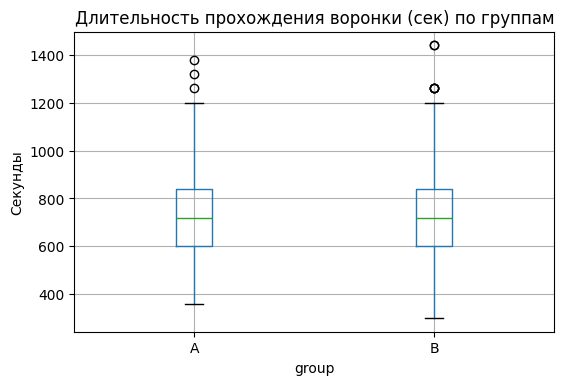

In [ ]:
import matplotlib.pyplot as plt
success_payments.boxplot(column='duration_sec', by='group', figsize=(6,4))
plt.title('Длительность прохождения воронки (сек) по группам')
plt.suptitle('')  # убирает автоматический заголовок "Boxplot grouped by group"
plt.ylabel('Секунды')
plt.show()

## 4. Однородность групп

Проверяю, что группы сопоставимы: для возраста — t-тест, для города и типа устройства — хи-квадрат с V Крамера.

       count       mean       std   min   25%   50%   75%   max
group                                                          
A      751.0  32.740346  7.815060  20.0  27.0  32.0  38.0  60.0
B      750.0  32.654667  7.775347  20.0  27.0  33.0  38.0  60.0


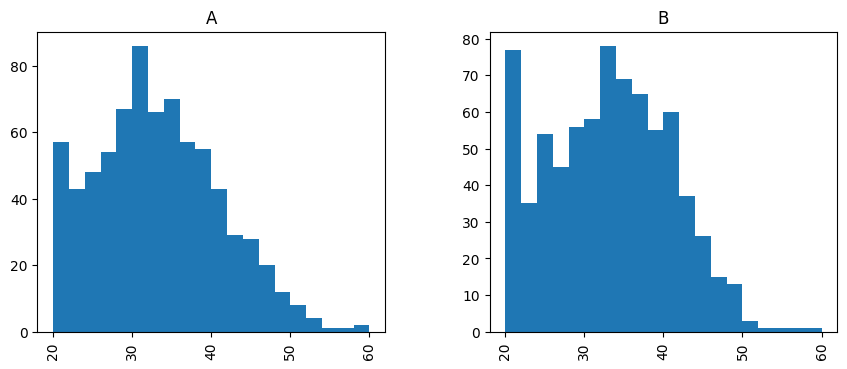

group     A    B
city            
Москва  288  306
Регион  268  246
СПб     195  199
group          A    B
device_type          
android      408  369
ios          344  382


In [ ]:
# 1. Age по группам — описательная статистика и гистограмма
print(users_clean.groupby('group')['age'].describe())

import matplotlib.pyplot as plt

users_clean.hist(column='age', by='group', bins=20, figsize=(10, 4))
plt.show()

# 2. City x group — таблица сопряжённости
city_crosstab = pd.crosstab(users_clean['city'], users_clean['group'])
print(city_crosstab)

# 3. Device_type x group — таблица сопряжённости
device_crosstab = pd.crosstab(users_clean['device_type'], users_clean['group'])
print(device_crosstab)

Выбросы у возраста есть, но на чувствительность t-теста они не повлияют: среднее и медиана почти равны, хвост не тяжёлый.

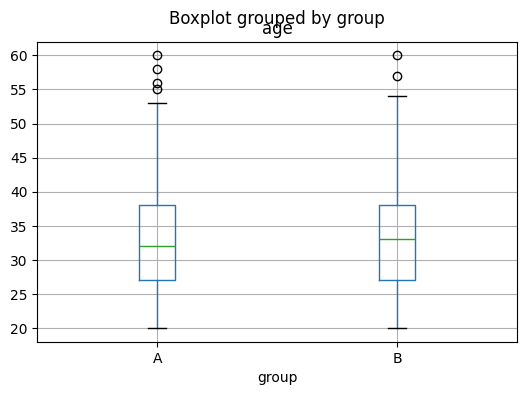

In [ ]:
users_clean.boxplot(column='age', by='group', figsize=(6,4))
plt.show()

### Тесты: t-test для возраста, хи-квадрат для города и устройства

In [ ]:
from scipy import stats
import numpy as np

# 1. T-test для age между группами A и B
age_A = users_clean[users_clean['group'] == 'A']['age'].dropna()
age_B = users_clean[users_clean['group'] == 'B']['age'].dropna()

t_stat, p_value_age = stats.ttest_ind(age_A, age_B, equal_var=False)
#print(f'T-test age: t={t_stat:.3f}, p={p_value_age:.3f}')

# 2. Хи-квадрат для city
chi2_city, p_city, dof_city, expected_city = stats.chi2_contingency(city_crosstab)
n_city = city_crosstab.sum().sum()
min_dim_city = min(city_crosstab.shape[0] - 1, city_crosstab.shape[1] - 1)
cramers_v_city = np.sqrt(chi2_city / (n_city * min_dim_city))
#print(f'Chi2 city: chi2={chi2_city:.3f}, p={p_city:.3f}, Cramér V={cramers_v_city:.3f}')

# 3. Хи-квадрат для device_type
chi2_device, p_device, dof_device, expected_device = stats.chi2_contingency(device_crosstab)
n_device = device_crosstab.sum().sum()
min_dim_device = min(device_crosstab.shape[0] - 1, device_crosstab.shape[1] - 1)
cramers_v_device = np.sqrt(chi2_device / (n_device * min_dim_device))
#print(f'Chi2 device: chi2={chi2_device:.3f}, p={p_device:.3f}, Cramér V={cramers_v_device:.3f}')

alpha = 0.05

results = pd.DataFrame([
    {
        'test': 'T-test (age)',
        'statistic': t_stat,
        'p_value': p_value_age,
        'effect_size': None,  # можно добавить Cohen's d отдельно, если нужно
        'alpha': alpha,
        'significant': p_value_age < alpha
    },
    {
        'test': 'Chi-square (city)',
        'statistic': chi2_city,
        'p_value': p_city,
        'effect_size': cramers_v_city,
        'alpha': alpha,
        'significant': p_city < alpha
    },
    {
        'test': 'Chi-square (device_type)',
        'statistic': chi2_device,
        'p_value': p_device,
        'effect_size': cramers_v_device,
        'alpha': alpha,
        'significant': p_device < alpha
    },
])

display(results)

,test,statistic,p_value,effect_size,alpha,significant
0,T-test (age),0.212916,0.831421,NaN,0.05,False
1,Chi-square (city),1.527698,0.465870,0.031892,0.05,False
2,Chi-square (device_type),3.743441,0.053015,0.049906,0.05,False


## 5. Воронка по шагам

На уровне каждого платежа определяю максимальный достигнутый шаг (1–4), затем агрегирую до пользователя: пользователь считается дошедшим до шага, если хотя бы один его платёж дошёл.

In [ ]:
# 1. На уровне каждого платежа определяем максимальный достигнутый шаг (1-4)
def max_step(row):
    if pd.notna(row['step4_success']):
        return 4
    elif pd.notna(row['step3_confirmed']):
        return 3
    elif pd.notna(row['step2_entered']):
        return 2
    elif pd.notna(row['step1_opened']):
        return 1
    else:
        return 0

payment_clean['max_step'] = payment_clean.apply(max_step, axis=1)

# 2. На уровне пользователя берём ЛУЧШИЙ результат из всех его платежей
user_funnel = payment_clean.groupby('user_id').agg(
    group=('group', 'first'),
    best_step=('max_step', 'max')
).reset_index()

# 3. Превращаем best_step в бинарные флаги достижения каждого шага
for step in [1, 2, 3, 4]:
    user_funnel[f'reached_step{step}'] = (user_funnel['best_step'] >= step).astype(int)

display(user_funnel.head())
display(user_funnel.groupby('group')[['reached_step1','reached_step2','reached_step3','reached_step4']].mean())

,user_id,group,best_step,reached_step1,reached_step2,reached_step3,reached_step4
0,1001,A,2,1,1,0,0
1,1002,A,2,1,1,0,0
2,1003,A,2,1,1,0,0
3,1004,A,4,1,1,1,1
4,1005,A,4,1,1,1,1


,reached_step1,reached_step2,reached_step3,reached_step4
group,,,,
A,1.0,0.894807,0.731025,0.65779
B,1.0,0.942667,0.858667,0.80400


In [ ]:
funnel_summary = user_funnel.groupby('group')[
    ['reached_step1','reached_step2','reached_step3','reached_step4']
].mean()

# транспонируем, чтобы шаги были строками, а группы - столбцами
funnel_summary = funnel_summary.T
funnel_summary.columns = ['A', 'B']

# абсолютная разница (в процентных пунктах)
funnel_summary['diff_abs_pp'] = (funnel_summary['B'] - funnel_summary['A']) * 100

# относительный прирост (в процентах от уровня A)
funnel_summary['diff_rel_pct'] = (funnel_summary['B'] - funnel_summary['A']) / funnel_summary['A'] * 100

display(funnel_summary.round(2))

,A,B,diff_abs_pp,diff_rel_pct
reached_step1,1.00,1.00,0.00,0.00
reached_step2,0.89,0.94,4.79,5.35
reached_step3,0.73,0.86,12.76,17.46
reached_step4,0.66,0.80,14.62,22.23


Виден явный прирост на шагах 2–3: относительный прирост +17,5% на переходе ко второму шагу подтверждает, что новая форма реально упрощает заполнение.

In [ ]:
import numpy as np
from scipy import stats

def wilson_ci(successes, n, alpha=0.05):
    return stats.proportion_confint(successes, n, alpha=alpha, method='wilson')

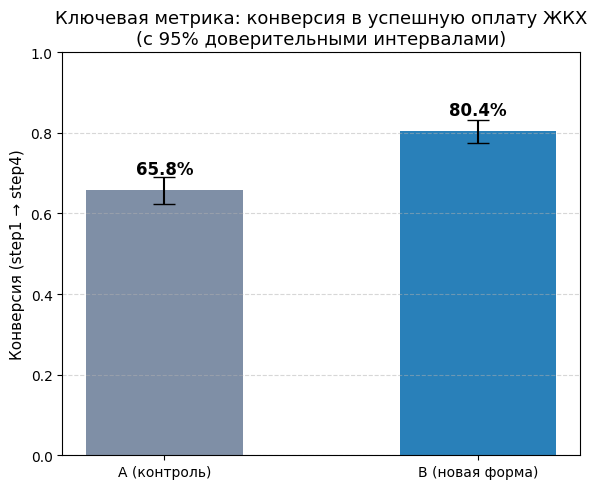

In [ ]:
from statsmodels.stats.proportion import proportion_confint

conv_a = funnel_summary.loc['reached_step4', 'A']
conv_b = funnel_summary.loc['reached_step4', 'B']
# считаем успехи и размеры групп
n_a = (user_funnel['group'] == 'A').sum()
n_b = (user_funnel['group'] == 'B').sum()
succ_a = user_funnel[user_funnel['group'] == 'A']['reached_step4'].sum()
succ_b = user_funnel[user_funnel['group'] == 'B']['reached_step4'].sum()

ci_a = proportion_confint(succ_a, n_a, alpha=0.05, method='wilson')
ci_b = proportion_confint(succ_b, n_b, alpha=0.05, method='wilson')

err_a = [conv_a - ci_a[0], ci_a[1] - conv_a]
err_b = [conv_b - ci_b[0], ci_b[1] - conv_b]

fig, ax = plt.subplots(figsize=(6, 5))
bars = ax.bar(['A (контроль)', 'B (новая форма)'], [conv_a, conv_b],
              yerr=[[err_a[0], err_b[0]], [err_a[1], err_b[1]]],
              capsize=8, color=['#7f8fa6', '#2980b9'], width=0.5)

for bar, value in zip(bars, [conv_a, conv_b]):
    ax.text(bar.get_x() + bar.get_width()/2, value + 0.04,
            f'{value*100:.1f}%', ha='center', fontsize=12, fontweight='bold')

ax.set_ylabel('Конверсия (step1 → step4)', fontsize=11)
ax.set_title('Ключевая метрика: конверсия в успешную оплату ЖКХ\n(с 95% доверительными интервалами)', fontsize=13)
ax.set_ylim(0, 1)
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('key_metric.png', dpi=150)
plt.show()

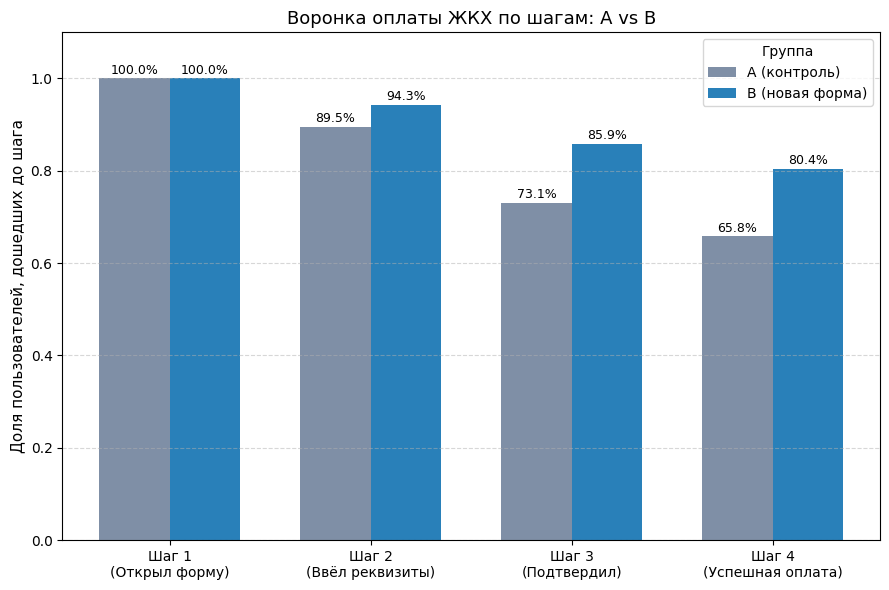

In [ ]:
steps = ['Шаг 1\n(Открыл форму)', 'Шаг 2\n(Ввёл реквизиты)', 'Шаг 3\n(Подтвердил)', 'Шаг 4\n(Успешная оплата)']
values_a = funnel_summary['A'].values
values_b = funnel_summary['B'].values

x = range(len(steps))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 6))
bars_a = ax.bar([i - width/2 for i in x], values_a, width, label='A (контроль)', color='#7f8fa6')
bars_b = ax.bar([i + width/2 for i in x], values_b, width, label='B (новая форма)', color='#2980b9')

for bars in [bars_a, bars_b]:
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 0.01, f'{h*100:.1f}%',
                ha='center', fontsize=9)

ax.set_xticks(list(x))
ax.set_xticklabels(steps, fontsize=10)
ax.set_ylabel('Доля пользователей, дошедших до шага', fontsize=11)
ax.set_title('Воронка оплаты ЖКХ по шагам: A vs B', fontsize=13)
ax.set_ylim(0, 1.1)
ax.legend(title='Группа', loc='upper right')
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('funnel_by_steps.png', dpi=150)
plt.show()

## 6. Статистическая значимость (z-test)

Односторонний тест: проверяю гипотезу «B > A» (новая форма увеличивает конверсию).

In [ ]:
from statsmodels.stats.proportion import proportions_ztest

# односторонний тест: проверяем гипотезу "B > A" (новая форма увеличивает конверсию)
count = np.array([succ_b, succ_a])   # порядок важен для направления теста
nobs = np.array([n_b, n_a])

z_stat, p_value = proportions_ztest(count, nobs, alternative='larger')

# доверительный интервал для разницы конверсий (B - A) — уже считали ci_a, ci_b по отдельности,
# но интереснее интервал именно для РАЗНИЦЫ
diff = conv_b - conv_a
se_diff = np.sqrt(conv_a*(1-conv_a)/n_a + conv_b*(1-conv_b)/n_b)
ci_diff = (diff - 1.96*se_diff, diff + 1.96*se_diff)

alpha = 0.05

main_test_results = pd.DataFrame([{
    'test': 'Z-test',
    'conv_A': conv_a,
    'conv_B': conv_b,
    'diff_pp': diff * 100,
    'ci_95_lower_pp': ci_diff[0] * 100,
    'ci_95_upper_pp': ci_diff[1] * 100,
    'statistic': z_stat,
    'p_value': p_value,
    'alpha': alpha,
    'significant': p_value < alpha
}])

display(main_test_results)

,test,conv_A,conv_B,diff_pp,ci_95_lower_pp,ci_95_upper_pp,statistic,p_value,alpha,significant
0,Z-test,0.65779,0.804,14.621039,10.195391,19.046686,6.385945,8.517111e-11,0.05,True


## 7. Время заполнения формы по группам

Проверяю, не куплен ли рост конверсии ценой: вдруг в B пользователи быстрее, но хуже заполняют форму.

In [ ]:
duration_by_group = success_payments.groupby('group')['duration_sec'].agg(['mean', 'median', 'std', 'count'])
display(duration_by_group)

,mean,median,std,count
group,,,,
A,744.846626,720.0,160.463445,652
B,741.241379,720.0,174.435995,870


## Выводы

1. **Конверсия в успешную оплату выросла с 65,8% до 80,4%** (+14,6 п.п., относительный прирост +22,2%); эффект статистически значим (односторонний z-тест, p = 8,5×10⁻¹¹, 95% ДИ [10,2; 19,0] п.п.).
2. **Максимальный прирост — на шаге «ввёл реквизиты → подтвердил»** (+12,8 п.п., +17,5% относительно): новая форма убирает именно трение заполнения.
3. **Группы однородны** (возраст: p = 0,83; город: p = 0,47; устройство: p = 0,053), время заполнения формы не различается (медиана 720 сек. в обеих группах) — эффект не объясняется составом аудитории.
4. **Рекомендация:** раскатить новую форму и мониторить конверсию по когортам 2–3 месяца — анализ ограничен одним платёжным циклом, устойчивость эффекта для повторных платежей не проверена.